# Economic Index Prediction: Linear Regression

**Goal:** Predict the `index_price` of an economic index using two economic indicators: `interest_rate` and `unemployment_rate`.

**Workflow:**
1. Import libraries and load the data
2. Explore the data (head, correlations, missing values, plots)
3. Clean the data (drop non-useful columns)
4. Define features (X) and target (y)
5. Split into training and test sets
6. Scale the features
7. Train a Linear Regression model
8. Evaluate the model (predictions, residuals, cross-validation, metrics)
9. Inspect the statistical summary

## 1. Import Libraries

- **pandas** (`pd`): loads and manipulates tabular data (DataFrames).
- **matplotlib.pyplot** (`plt`): low-level plotting library used to draw charts.
- **seaborn** (`sns`): built on top of matplotlib; produces statistical plots with less code.
- **numpy** (`np`): fast numerical arrays and math functions.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## 2. Load the Dataset

`pd.read_csv` reads the CSV file into a DataFrame `df`, where each row is one month of observations and each column is a variable.

In [3]:
df = pd.read_csv('economic_index.csv')

## 3. Preview the Data

`df.head()` shows the first 5 rows. This lets us confirm the file loaded correctly and see the column names and typical values.

The columns are:
- `Unnamed: 0`: an index column that was saved with the CSV (not a real feature).
- `year`, `month`: when the observation was recorded.
- `interest_rate`: the interest rate (%) at that time.
- `unemployment_rate`: the unemployment rate (%).
- `index_price`: the value of the economic index (our target).

In [4]:
df.head()

,Unnamed: 0,year,month,interest_rate,unemployment_rate,index_price
0,0,2017,12,2.75,5.3,1464
1,1,2017,11,2.50,5.3,1394
2,2,2017,10,2.50,5.3,1357
3,3,2017,9,2.50,5.3,1293
4,4,2017,8,2.50,5.4,1256


## 4. Correlation Matrix (Before Cleaning)

`df.corr()` computes the **Pearson correlation** between every pair of numeric columns.

- Values range from **-1 to +1**.
- **+1** means the two variables rise together perfectly; **-1** means one rises as the other falls; **0** means no linear relationship.
- We look at the `index_price` row to see which features move with the target.
- `Unnamed: 0` and `year` correlate strongly with the target only because they are time-ordered (the index trends over time). They are not real economic drivers, which is why we remove them next.
- `month` shows the weakest link, so it is also not a useful predictor here.

In [5]:
df.corr()

,Unnamed: 0,year,month,interest_rate,unemployment_rate,index_price
Unnamed: 0,1.000000,-8.667781e-01,-4.986939e-01,-0.934555,0.935300,-0.988246
year,-0.866778,1.000000e+00,7.884865e-14,0.882851,-0.877000,0.863232
month,-0.498694,7.884865e-14,1.000000e+00,0.339526,-0.351189,0.481287
interest_rate,-0.934555,8.828507e-01,3.395257e-01,1.000000,-0.925814,0.935793
unemployment_rate,0.935300,-8.769997e-01,-3.511891e-01,-0.925814,1.000000,-0.922338
index_price,-0.988246,8.632321e-01,4.812873e-01,0.935793,-0.922338,1.000000


## 5. Drop Irrelevant Columns

We remove:
- `Unnamed: 0`: a leftover row index from saving the CSV. It carries no information.
- `year` and `month`: time labels. Keeping them would let the model learn the time trend instead of the economic relationship we care about.

`axis=1` means we drop **columns** (not rows), and `inplace=True` modifies `df` directly instead of returning a copy.

In [6]:
df.drop(columns=['Unnamed: 0', 'year', 'month'], axis=1, inplace=True)

## 6. Check the Cleaned Data

Printing `df` shows the remaining columns: `interest_rate`, `unemployment_rate`, and `index_price`. Each of the 24 rows is one month's observation.

In [7]:
df

,interest_rate,unemployment_rate,index_price
0,2.75,5.3,1464
1,2.50,5.3,1394
2,2.50,5.3,1357
3,2.50,5.3,1293
4,2.50,5.4,1256
5,2.50,5.6,1254
6,2.50,5.5,1234
7,2.25,5.5,1195
8,2.25,5.5,1159
9,2.25,5.6,1167


## 7. Correlation Matrix (After Cleaning)

Now that only the economic variables remain, the correlation matrix shows their true relationships:
- **interest_rate vs index_price ≈ +0.94**: strong positive relationship. Higher rates go with a higher index.
- **unemployment_rate vs index_price ≈ -0.92**: strong negative relationship. Higher unemployment goes with a lower index.
- **interest_rate vs unemployment_rate ≈ -0.93**: these two are strongly correlated with each other. This is called **multicollinearity**, which can make individual coefficients less stable, but it does not stop the model from predicting well.

In [8]:
df.corr()

,interest_rate,unemployment_rate,index_price
interest_rate,1.000000,-0.925814,0.935793
unemployment_rate,-0.925814,1.000000,-0.922338
index_price,0.935793,-0.922338,1.000000


## 8. Check for Missing Values

`isnull().sum()` counts missing (`NaN`) values in each column. All zeros means the data is complete and no imputation is needed.

In [9]:
df.isnull().sum()

interest_rate        0
unemployment_rate    0
index_price          0
dtype: int64

## 9. Pairplot: Visualize All Relationships

`sns.pairplot` draws a grid:
- **Diagonal:** the distribution of each variable (histogram or density).
- **Off-diagonal:** scatter plots of each pair of variables.

Use it to spot linear trends, outliers, and whether the relationships look roughly linear, which is what Linear Regression assumes.

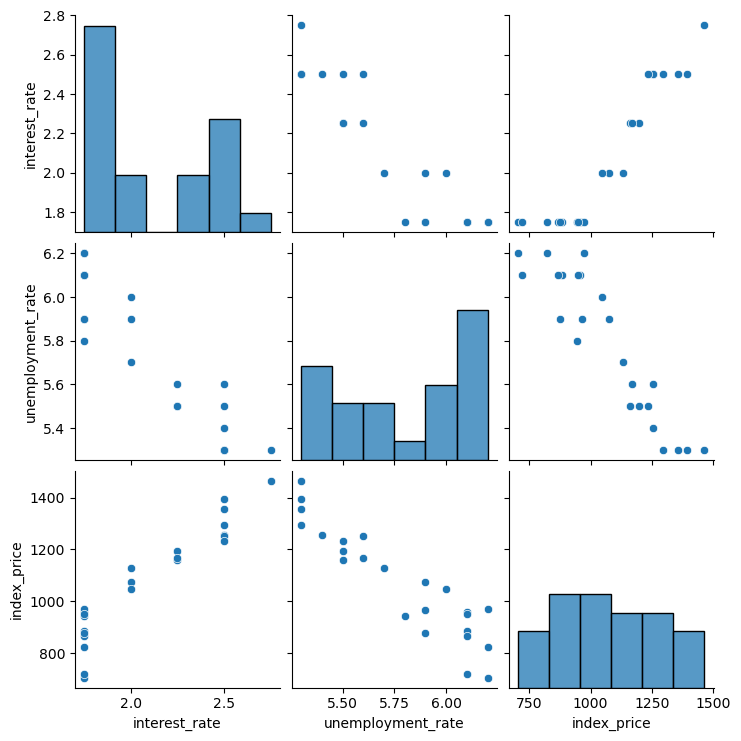

In [10]:
sns.pairplot(df)

## 10. Scatter Plot: Interest Rate vs Unemployment Rate

`plt.scatter` plots each row as a point. Here we look at the two input features against each other. The downward-sloping pattern confirms the strong negative correlation seen earlier (when rates go up, unemployment tends to come down).

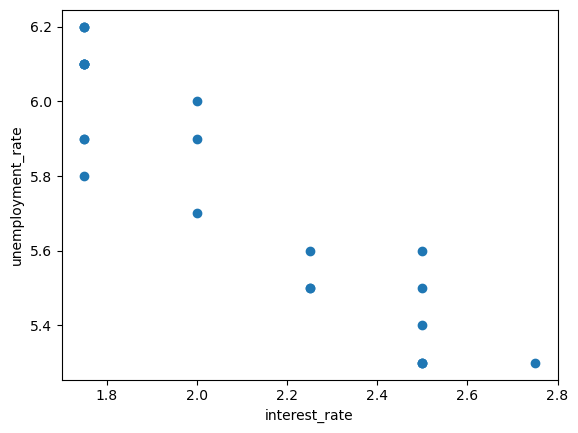

In [11]:
plt.scatter(df['interest_rate'], df['unemployment_rate'])
plt.xlabel('interest_rate')
plt.ylabel('unemployment_rate')
plt.show()

## 11. Define Features (X) and Target (y)

- **X** (features / independent variables): the inputs the model uses to predict. Here, `interest_rate` and `unemployment_rate`. Note the double brackets: they keep X as a 2-column DataFrame.
- **y** (target / dependent variable): what we want to predict, `index_price`. Single brackets make it a 1-D Series.

In [12]:
# Independent features (inputs)
X = df[['interest_rate', 'unemployment_rate']]
# Dependent target (what we predict)
y = df['index_price']

In [13]:
X

,interest_rate,unemployment_rate
0,2.75,5.3
1,2.50,5.3
2,2.50,5.3
3,2.50,5.3
4,2.50,5.4
5,2.50,5.6
6,2.50,5.5
7,2.25,5.5
8,2.25,5.5
9,2.25,5.6


In [14]:
y

0     1464
1     1394
2     1357
3     1293
4     1256
5     1254
6     1234
7     1195
8     1159
9     1167
10    1130
11    1075
12    1047
13     965
14     943
15     958
16     971
17     949
18     884
19     866
20     876
21     822
22     704
23     719
Name: index_price, dtype: int64

## 12. Train-Test Split

`train_test_split` divides the data into:
- **Training set (75%):** the model learns from these rows.
- **Test set (25%):** rows the model never sees during training, used to judge how well it generalizes to new data.

`random_state=42` fixes the random shuffle so the split is reproducible. Without this, every run would give a different split and different scores.

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,     # 25% of rows go to the test set
    random_state=42     # fixed seed for a reproducible shuffle
)

## 13. Feature Scaling (Standardization)

`StandardScaler` transforms each feature to have mean 0 and standard deviation 1:

$$z = \frac{x - \mu}{\sigma}$$

Why it matters:
- The two features are on different scales (interest rates around 2 vs. unemployment around 6). Scaling puts them on a comparable footing so the coefficients are easier to compare.
- **We fit the scaler on the training data only.** Fitting on the test set would leak information about test-set statistics into training (data leakage), giving falsely optimistic results. The test set is then transformed using the training mean and standard deviation, mirroring how new real-world data would be handled.

In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Learn mean and std from the TRAINING data, then apply them to training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply the SAME training mean and std to test data (no fitting on test data)
X_test_scaled = scaler.transform(X_test)

In [17]:
X_train_scaled

array([[-0.90115511,  0.37908503],
       [ 1.31077107, -1.48187786],
       [-0.90115511,  1.30956648],
       [ 1.31077107, -0.55139641],
       [ 1.31077107, -1.48187786],
       [-0.16384638,  0.68924552],
       [-0.90115511,  0.999406  ],
       [ 1.31077107, -1.48187786],
       [ 1.31077107, -1.17171738],
       [-0.90115511,  1.30956648],
       [-0.90115511,  0.999406  ],
       [-0.90115511,  0.37908503],
       [-0.90115511,  0.999406  ],
       [ 0.57346234, -0.8615569 ],
       [-0.16384638, -0.24123593],
       [-0.90115511,  0.06892455],
       [-0.90115511,  0.999406  ],
       [ 1.31077107, -0.8615569 ]])

## 14. Regression Plot with Confidence Band

`sns.regplot` draws:
- the scatter of points (`interest_rate` vs `index_price`),
- a **red best-fit line** from linear regression,
- a shaded **95% confidence interval** around that line, showing how uncertain the fitted trend is.

The upward slope shows that higher interest rates are associated with a higher index price.

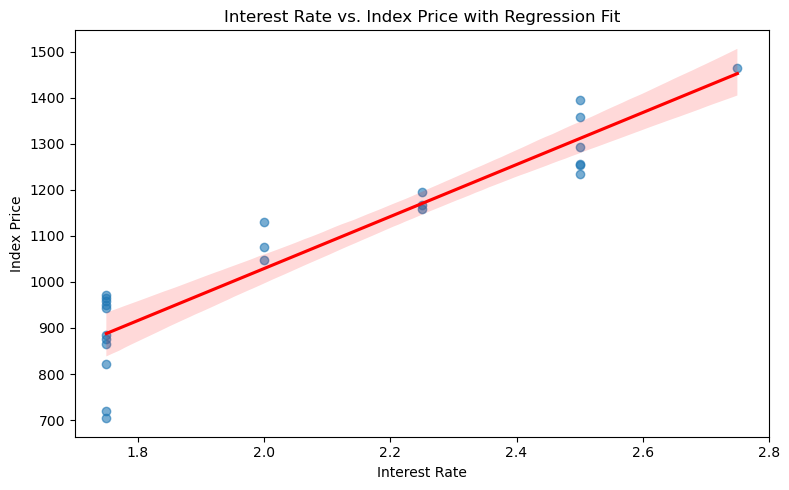

In [18]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=df,
    x='interest_rate',               # predictor on x-axis
    y='index_price',                 # target on y-axis
    scatter_kws={'alpha': 0.6},      # semi-transparent points reveal overlap
    line_kws={'color': 'red'}        # highlight the fitted line
)

plt.title('Interest Rate vs. Index Price with Regression Fit')
plt.xlabel('Interest Rate')
plt.ylabel('Index Price')
plt.tight_layout()
plt.show()

## 15. Train the Linear Regression Model

`LinearRegression` fits the equation:

$$\text{index\_price} = b_0 + b_1 \cdot \text{interest\_rate}_{\text{scaled}} + b_2 \cdot \text{unemployment\_rate}_{\text{scaled}}$$

`.fit()` finds the coefficients $b_1, b_2$ and intercept $b_0$ that minimize the sum of squared errors on the training data (ordinary least squares).

In [2]:
'''fit() runs an optimization process in a loop:
1. Makes an initial guess: The model starts with random internal parameters (weights and biases) and uses them to make predictions on X_train_scaled.
2. Measures its mistakes: It compares those predictions against the actual ground-truth answers in y_train using a loss function (such as Mean Squared Error for regression or Cross-Entropy for classification).
3. Adjusts its parameters: Using an algorithm like gradient descent, the model updates its internal weights to reduce those errors.
4. Repeats until optimized: It repeats this cycle until it finds the best mathematical pattern that maps X_train_scaled to y_train.'''

'fit() runs an optimization process in a loop:\n1. Makes an initial guess: The model starts with random internal parameters (weights and biases) and uses them to make predictions on X_train_scaled.\n2. Measures its mistakes: It compares those predictions against the actual ground-truth answers in y_train using a loss function (such as Mean Squared Error for regression or Cross-Entropy for classification).\n3. Adjusts its parameters: Using an algorithm like gradient descent, the model updates its internal weights to reduce those errors.\n4. Repeats until optimized: It repeats this cycle until it finds the best mathematical pattern that maps X_train_scaled to y_train.'

In [19]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_scaled, y_train)

LinearRegression()

## 16. Model Parameters

- **`intercept_`**: the predicted `index_price` when every scaled feature is 0, i.e. when both inputs equal their training averages.
- **`coef_`**: how much the prediction changes per one-standard-deviation increase in each feature, holding the other fixed.
  - Positive coefficient for `interest_rate`: higher rates push the index up.
  - Negative coefficient for `unemployment_rate`: higher unemployment pulls the index down.

In [20]:
print(model.intercept_)

1053.4444444444443


In [21]:
print(model.coef_)

[  88.27275507 -116.25716066]


## 17. Make Predictions on the Test Set

`.predict()` applies the learned equation to the scaled test features and returns the predicted `index_price` for each test row. These are compared with the true values next.

In [3]:
'''y_pred = model.predict(X_test_scaled) uses your trained model to generate predictions for the unseen
   test data (X_test_scaled) and saves those predicted answers into a variable called y_pred.'''

'y_pred = model.predict(X_test_scaled) uses your trained model to generate predictions for the unseen\n   test data (X_test_scaled) and saves those predicted answers into a variable called y_pred.'

In [22]:
y_pred = model.predict(X_test_scaled)

## 18. Actual vs Predicted

Each point is one test observation: x-axis is the true value, y-axis is the prediction. If the model were perfect, all points would lie on the diagonal. Points close to a line from bottom-left to top-right indicate good predictions.

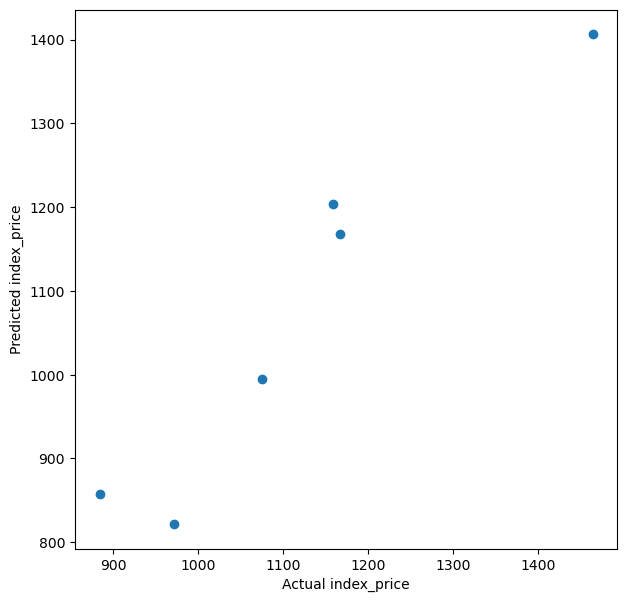

In [23]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred)
plt.xlabel('Actual index_price')
plt.ylabel('Predicted index_price')
plt.show()

## 19. Residuals

A **residual** is the error for one prediction: `actual − predicted`.

Good residuals should:
- be centered around 0 (no systematic over- or under-prediction),
- look roughly normally distributed (checked with the KDE plot below),
- show no clear pattern when plotted against predictions (checked in the next plot).

In [24]:
residual = y_test - y_pred

### 19a. Residual Distribution

`sns.displot(..., kind='kde')` draws a kernel density estimate: a smooth curve of how residuals are distributed. A bell shape centered near 0 is what we want.

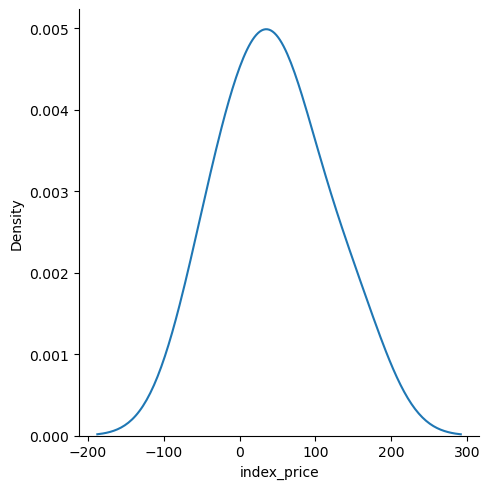

In [25]:
sns.displot(residual, kind='kde')

### 19b. Residuals vs Predictions

Plotting residuals against predicted values checks for **homoscedasticity** (constant error spread). Random scatter around zero is good. A funnel shape or curve would suggest the linear model is missing something.

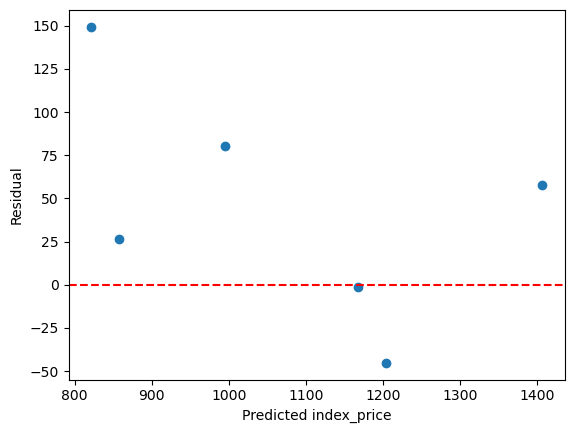

In [26]:
plt.scatter(y_pred, residual)
plt.xlabel('Predicted index_price')
plt.ylabel('Residual')
plt.axhline(0, color='red', linestyle='--')
plt.show()

## 20. Cross-Validation

`cross_val_score` splits the full data into 5 folds. It trains on 4 folds and tests on the remaining one, rotating so each fold is the test set once. The result is 5 R² scores.

- **R²** (coefficient of determination) measures how much variance in the target the model explains. 1.0 is perfect; 0 means no better than predicting the mean; negative means worse than the mean.

With only 24 rows, each fold has very few points, so the scores vary a lot. The large negative values below reflect that small-sample instability, not necessarily a broken model.

In [27]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(model, X, y, cv=5, scoring='r2')
print(scores)

[ 0.56590849 -0.25461029  0.14743258 -5.98513309 -4.05485945]


## 21. Evaluation Metrics

- **MAE (Mean Absolute Error):** average size of the error, in the same units as `index_price`. Easy to interpret.
- **RMSE (Root Mean Squared Error):** like MAE but squares errors first, so large misses are penalized more heavily.
- **R² (on test set):** fraction of variance in the test target explained by the model.

In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [29]:
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5   # square root of MSE
r2 = r2_score(y_test, y_pred)

print(f'MAE:  {mae:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'R²:   {r2:.3f}')

MAE:  59.94
RMSE: 76.12
R²:   0.828


## 22. Statistical Summary with statsmodels

`statsmodels` gives a more detailed statistical report than scikit-learn:
- **coef / std err / t / P>|t|:** each coefficient's estimate, uncertainty, and significance. A p-value below 0.05 usually means the feature is statistically significant.
- **R-squared** and **Adj. R-squared:** goodness of fit.
- **Durbin-Watson:** tests for autocorrelation in residuals. Values near 2 are good.
- **Jarque-Bera / Skew / Kurtosis:** check whether the residuals are normal.
- **Cond. No.:** a high value signals multicollinearity.

**Note:** this model is fitted on the *unscaled* `X_train`, so its coefficients are in original units. The `add_constant` step is not used here, which is why the report says R² is uncentered.

In [30]:
import statsmodels.api as sm

sm_model = sm.OLS(y_train, X_train).fit()
sm_model.summary()

e:\anaconda\envs\abdullah\Lib\site-packages\scipy\stats\_axis_nan_policy.py:430: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=18 observations were given.
  return hypotest_fun_in(*args, **kwds)


<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:            index_price   R-squared (uncentered):                   0.995
Model:                            OLS   Adj. R-squared (uncentered):              0.994
Method:                 Least Squares   F-statistic:                              1468.
Date:                Wed, 25 Nov 2026   Prob (F-statistic):                    7.46e-19
Time:                        22:54:55   Log-Likelihood:                         -104.21
No. Observations:                  18   AIC:                                      212.4
Df Residuals:                      16   BIC:                                      214.2
Df Model:                           2                                                  
Covariance Type:            nonrobust                                                  
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
interest_rate       569.9494     44.349     12.851      0.000     475.933     663.965
unemployment_rate   -20.5734     15.966     -1.289      0.216     -54.421      13.274
==============================================================================
Omnibus:                        1.657   Durbin-Watson:                   1.707
Prob(Omnibus):                  0.437   Jarque-Bera (JB):                1.346
Skew:                          -0.611   Prob(JB):                        0.510
Kurtosis:                       2.451   Cond. No.                         14.6
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## 23. Summary of Findings

- Interest rate and unemployment rate both have strong linear relationships with `index_price`.
- The two features are themselves strongly correlated (multicollinearity), so individual coefficient values should be read with caution.
- The model's test-set R², MAE, and RMSE quantify its predictive accuracy.
- Cross-validation scores vary widely because the dataset is small (24 rows); more data would make the estimates more reliable.

**Possible next steps:** collect more observations, try regularized models (Ridge/Lasso) to handle multicollinearity, or test non-linear models if residual plots show a pattern.

In [4]:

'''Feature	        OLS (Ordinary Least Squares)	                                                             Gradient Descent (SGDRegressor, Neural Nets)
How it solves	Closed-form math equation: Calculates the exact optimal answer in one single step.	    Iterative guessing: Takes hundreds/thousands of small steps to gradually reduce err
'''

'Feature\t        OLS (Ordinary Least Squares)\t                                                             Gradient Descent (SGDRegressor, Neural Nets)\nHow it solves\tClosed-form math equation: Calculates the exact optimal answer in one single step.\t    Iterative guessing: Takes hundreds/thousands of small steps to gradually reduce err\n'